**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**27 | Final HARTH Research Evidence Synthesis and Reproducibility Report**

![Stage 27 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/27_workflow.svg)

**Objective:** Consolidate recorded evidence from HARTH Stages 23–26 and examine its provenance, evaluation boundaries, model comparisons and reproducibility.

**Evidence Sources:** Saved research notebooks, protocol manifests and recorded evaluation outputs. This Notebook does not download raw HARTH recordings, load model weights or access reserved Test source files.

**Notebook Scope:** Read and verify saved benchmark, robustness, model-selection and qualified held-out evidence without retraining or generating new predictions. Stages 23–24 report Development results; Stage 26 reports a qualified same-study held-out evaluation involving two participants previously inspected descriptively, not blind external validation.

**Evidence checks:** Inspect source fingerprints, saved execution records and Quality Gates. Retain the precision of the recorded tables, usually four decimal places, and do not reconstruct missing metrics.

**00. Colab Repository Setup**

Prepare the repository using the Code Cell below. The report reads recorded results without training or evaluating the models again.

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


**01. Imports and Evidence-Reading Utilities**

In [ ]:
# ================ 01. Imports and Evidence-Reading Utilities =================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
import hashlib
import json

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display

# -------------- 5. Saved Evidence and Research Report Utilities --------------
from core.harth_selection_evidence import load_selection_evidence
from core.harth_study_report import load_final_harth_evidence, _load_executed_notebook

# ------------------------- 6. Scientific Plot Style --------------------------
from core.plot_style import plot_style
plot_style()

# ------------------------- 7. Saved Research Sources -------------------------
base = root / "wearable_activity_recognition"
notebook_dir = base / "code/notebooks"
stage23 = notebook_dir / "23_unified_matched_model_benchmark.ipynb"
stage24 = notebook_dir / "24_multiseed_and_imbalance_robustness.ipynb"
stage25 = notebook_dir / "25_model_selection_and_protocol_freeze.ipynb"
stage26 = notebook_dir / "26_final_development_training_and_inference.ipynb"
manifest_pending = base / "evidence/stage_25_protocol_proposal_reconciled.json"
manifest_approved = base / "evidence/stage_25_protocol_approved_qualified_test.json"

# ---------------------- 8. Read Saved Research Results -----------------------
development = load_selection_evidence(stage23, stage24)
final = load_final_harth_evidence(
    stage26, manifest_pending, manifest_approved, development["development_sha256"]
)
_, h25 = _load_executed_notebook(stage25, "Stage 25 development selection audit: PASSED")
print("STAGE 27 | SOURCE-GROUNDED HARTH REPORT")
print("Saved research results loaded; no new training or Test evaluation.")


STAGE 27 | SOURCE-GROUNDED HARTH REPORT
Executed Stages 23, 24, 25, 26: VERIFIED
Development fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Stage 26 notebook SHA256: 03d22083b48db46771a0b880da66e32b66a79d7f0bee010298590ef77f62f31c
Original Test CSVs read by Stage 27: NO
Models trained or scored by Stage 27: NO


**02. Dataset, Cohort and Experimental Design**

The source is pinned HARTH v2.0 from the NTNU AI Lab source repository, not the older UCI HARTH release. Six lower-back/right-thigh accelerometer channels sampled at nominal 50 Hz are windowed to 100 samples with stride 50, strict annotation purity and continuity. Eight original documented class codes are used; undocumented codes are not given invented activity names. A label-independent cap of 500 windows per person yields 14,201 Development windows from 29 people. Test uses 500 eligible windows each from S023 and S032, who had been inspected in earlier exploration. Correlated overlapping windows are not independent observations.

In [ ]:
# ================ 02. Dataset, Cohort and Experimental Design ================

source = final["approved_manifest"]["source"]
primary = final["approved_manifest"]["primary_model"]
reference = final["approved_manifest"]["reference_model"]
protocol_rows = [
    ("Source dataset", source["dataset"]),
    ("Pinned revision", source["revision"]),
    ("Development people", source["development_participants"]),
    ("Development windows", source["expected_development_windows"]),
    ("Reserved Test people", ", ".join(source["reserved_test_people"])),
    ("Test cap per person", source["test_cap_per_person"]),
    ("Sampling frequency (Hz)", source["sampling_rate_hz"]),
    ("Window / stride (samples)", f'{source["window_size"]} / {source["step_size"]}'),
    ("Classification codes", str(source["task_codes"])),
    ("Primary network", primary["architecture"]),
    ("Fixed optimiser updates", primary["optimizer_steps"]),
    ("Class weighting", primary["training_loss"]),
    ("Random Forest trees", reference["n_estimators"]),
]
display(pd.DataFrame(protocol_rows, columns=["Protocol component", "Recorded setting"]))
display(final["coverage"])
assert final["coverage"]["sampled_windows"].sum() == 1000


,Protocol component,Recorded setting
0,Source dataset,HARTH v2.0
1,Pinned revision,dad2cfbe89a26f72f19770419469ac037de200df
2,Development people,29
3,Development windows,14201
4,Reserved Test people,"S023, S032"
5,Test cap per person,500
6,Sampling frequency (Hz),50
7,Window / stride (samples),100 / 50
8,Classification codes,"[1, 2, 3, 4, 5, 6, 7, 8]"
9,Primary network,1D-ResNet


,subject_id,eligible_windows,sampled_windows
0,S023,2567,500
1,S032,3037,500


**03. Seven-Model Matched Development Comparison (Stage 23)**

Seven predeclared classifiers were evaluated using the same 29 Development participants and three subject-disjoint folds. Compare saved mean Macro F1, observed variability, accuracy and computational cost. Architecture, features and training-loss choice can differ between systems; a ranking is descriptive, not a causal architecture-only experiment.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.9468,33.0217,0.1304,91176
1,TCN,0.8138,0.0658,0.8575,0.9365,9.3827,0.1335,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,13.3388,0.1800,0
3,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,13.2878,0.3920,38744
4,Multi-Scale CNN,0.7946,0.0459,0.8392,0.9364,8.7932,0.1501,16488
5,Weighted CNN,0.7725,0.0274,0.8022,0.9412,4.2729,0.0480,12392
6,Standard CNN,0.6664,0.0633,0.6575,0.9378,7.5230,0.1166,12392


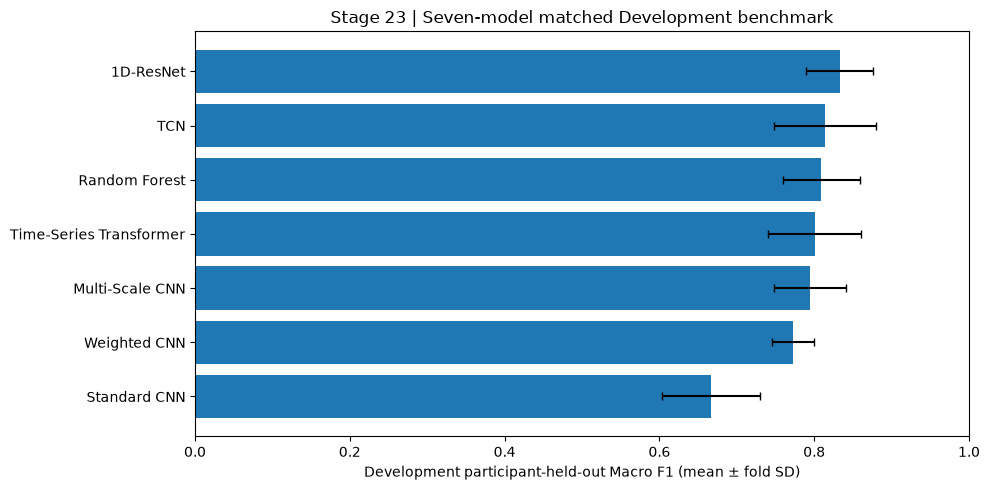

In [ ]:
# ========= 03. Seven-Model Matched Development Comparison (Stage 23) =========

# -------------------- 1. Seven-Model Development Results ---------------------
benchmark = development["stage23"].sort_values("macro_f1_mean", ascending=False)
assert len(benchmark) == 7
display(benchmark.round(4))

# --------------------- 2. Fixed-Task Macro F1 Comparison ---------------------
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(benchmark["model"][::-1], benchmark["macro_f1_mean"][::-1],
        xerr = benchmark["macro_f1_sd"][::-1], capsize=3)
ax.set_xlabel("Development participant-held-out Macro F1 (mean ± fold SD)")
ax.set_title("Stage 23 | Seven-model matched Development benchmark")
ax.set_xlim(0, 1)
fig.tight_layout()
plt.show()


**04. Repeated-Seed Robustness and Training-Loss Comparisons (Stage 24)**

Stage 24 evaluated 36 model/fold/seed jobs using seeds 42, 123 and 2026 across three disjoint Development folds. Report all four selected model/loss conditions rather than only the winning configuration. Across-seed SD refers to variation among three seed-level fold averages; it is not a confidence interval or independent cohort replication.

,architecture,loss_method,mean_across_seed_fold_macro_f1,across_seed_sd,total_training_s
0,1D-ResNet,weighted_ce,0.8286,0.0052,99.7251
1,TCN,weighted_ce,0.8105,0.0079,27.7609
2,1D-ResNet,focal,0.8058,0.0053,99.9784
3,1D-ResNet,class_balanced,0.7915,0.0191,99.5433


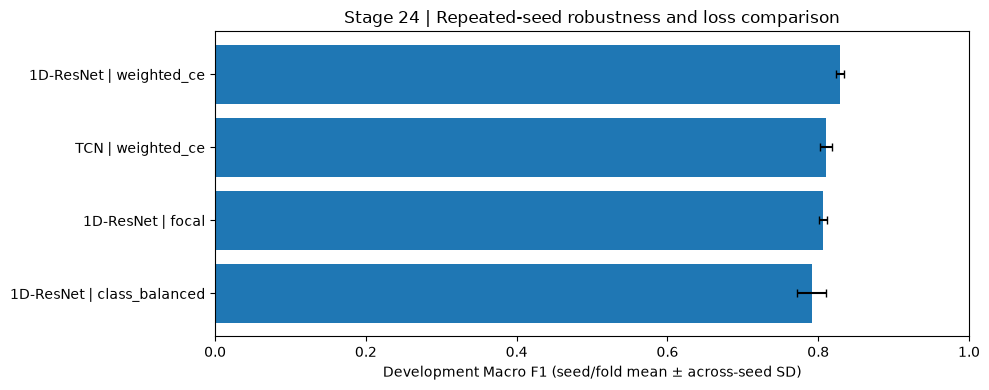

In [ ]:
# === 04. Repeated-Seed Robustness and Training-Loss Comparisons (Stage 24) ===

# --------------------- 1. Multi-Seed and Loss Robustness ---------------------
robust = development["stage24_summary"].sort_values(
    "mean_across_seed_fold_macro_f1", ascending=False
)
assert len(development["stage24_folds"]) == 36 and len(robust) == 4
display(robust.round(4))

# ---------------------- 2. Seed Stability Visualisation ----------------------
labels = robust["architecture"].astype(str)+" | "+robust["loss_method"].astype(str)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(labels[::-1], robust["mean_across_seed_fold_macro_f1"][::-1],
        xerr = robust["across_seed_sd"][::-1], capsize=3)
ax.set_xlim(0, 1)
ax.set_xlabel("Development Macro F1 (seed/fold mean ± across-seed SD)")
ax.set_title("Stage 24 | Repeated-seed robustness and loss comparison")
fig.tight_layout()
plt.show()


**05. Frozen Model Selection and Development Fit**

The selected primary was a 1D-ResNet with inverse-square-root weighted cross-entropy, 400 Adam updates, batch size 128, learning rate 0.001 and seed 42. The reference was a 120-tree Random Forest with 30 statistical features and fixed hyperparameters. Final fitting used 29 Development people only, without Test tuning. The saved Stage 26 Development inference reload check passed. Detailed model weights remain ignored local artefacts, not necessarily present in a new runtime. Stage 25 was selection on Development, not independent confirmation.

In [ ]:
# ============== 05. Frozen Model Selection and Development Fit ===============

# ------------------- 1. Frozen Development Model Selection -------------------
decision = pd.DataFrame([
    {"Role":"Preselected primary", "Model":"1D-ResNet Weighted CE",
     "Selection basis":"Development Stage 23/24"},
    {"Role":"Predeclared reference", "Model":"Random Forest",
     "Selection basis":"Development Stage 23/24"},
])
display(decision)

# ---------------------- 2. No Test-Driven Model Tuning -----------------------
assert primary["architecture"] == "1D-ResNet" and primary["optimizer_steps"] == 400
assert reference["n_estimators"] == 120
assert final["approved_manifest"]["evaluation"]["use_test_for_tuning"] is False
print("Model choice frozen before qualified Test: YES")
print("Test-driven hyperparameter/model changes permitted: NO")


,Role,Model,Selection basis
0,Preselected primary,1D-ResNet Weighted CE,Development Stage 23/24
1,Predeclared reference,Random Forest,Development Stage 23/24


Model choice frozen before qualified Test: YES
Test-driven hyperparameter/model changes permitted: NO


**06. Qualified Held-Out Evaluation (Stage 26)**

The original reserved Test participants were S023 and S032, with 500 windows selected from eligible recordings for each person under the approved protocol. The saved Stage 26 results report fixed eight-class Macro F1 of **0.7182** for weighted 1D-ResNet and **0.6817** for Random Forest. These figures are read from the earlier evaluation, not recomputed here. Balanced accuracy averages recall over classes observed in each evaluated subset; its class denominator can differ from the fixed eight-class Macro F1 denominator. The two models show different accuracy and class-specific error profiles.

,model,windows,subjects,fixed_eight_class_macro_f1,balanced_accuracy_observed_classes,accuracy,true_classes_present
0,1D-ResNet Weighted CE,1000,2,0.7182,0.9234,0.902,8
1,Random Forest,1000,2,0.6817,0.7599,0.927,8


,model,subject_id,windows,true_classes_present,fixed_eight_class_macro_f1,balanced_accuracy_observed_classes,accuracy
0,1D-ResNet Weighted CE,S023,500,8,0.7384,0.9559,0.900
1,1D-ResNet Weighted CE,S032,500,6,0.5662,0.8509,0.904
2,Random Forest,S023,500,8,0.7391,0.8376,0.956
3,Random Forest,S032,500,6,0.4597,0.6826,0.898


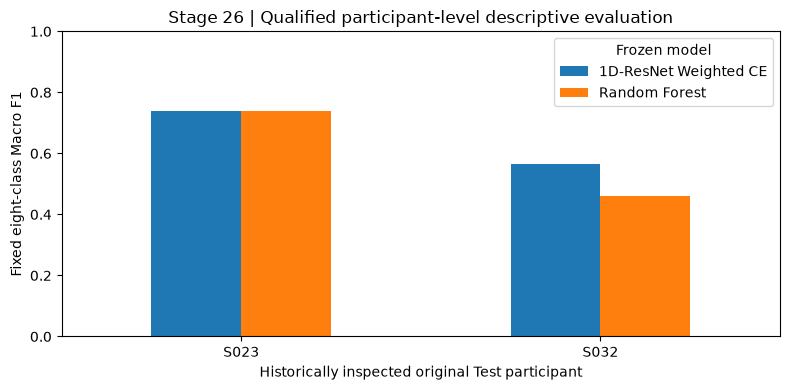

In [ ]:
# =============== 06. Qualified Held-Out Evaluation (Stage 26) ================

# ----------------- 1. Qualified Test Summary and Individuals -----------------
display(final["summary"].round(4))
display(final["per_subject"].round(4))

# --------------------- 2. Fixed-Task Participant Scores ----------------------
fig, ax = plt.subplots(figsize=(8, 4))
pivot = final["per_subject"].pivot(index="subject_id", columns="model",
                                values = "fixed_eight_class_macro_f1")
pivot.plot.bar(ax=ax, ylim=(0, 1), rot=0)
ax.set_ylabel("Fixed eight-class Macro F1")
ax.set_xlabel("Historically inspected original Test participant")
ax.set_title("Stage 26 | Qualified participant-level descriptive evaluation")
ax.legend(title="Frozen model")
fig.tight_layout()
plt.show()


**07. Activity-Level Errors, Actual Support and Class Imbalance**

Report precision, recall, F1 and true support for all eight source classes. The qualified held-out subset contains only **3 Shuffling**, **10 Stairs ascending** and **6 Stairs descending** windows. High recall on such small groups is unstable evidence and does not establish reliable recognition for unseen participants. Confusion matrices remain in Notebook 26; their counts are not inferred from rounded metrics.

,model,source_code,activity,precision,recall,f1,support
0,1D-ResNet Weighted CE,1,Walking,0.9959,0.8941,0.9422,538
1,1D-ResNet Weighted CE,2,Running,0.9348,1.0000,0.9663,86
2,1D-ResNet Weighted CE,3,Shuffling,0.1364,1.0000,0.2400,3
3,1D-ResNet Weighted CE,4,Stairs ascending,0.4444,0.8000,0.5714,10
4,1D-ResNet Weighted CE,5,Stairs descending,0.2143,1.0000,0.3529,6
5,1D-ResNet Weighted CE,6,Standing,0.9888,0.6929,0.8148,127
6,1D-ResNet Weighted CE,7,Sitting,0.7516,1.0000,0.8582,115
7,1D-ResNet Weighted CE,8,Lying,1.0000,1.0000,1.0000,115
8,Random Forest,1,Walking,0.9773,0.9610,0.9691,538
9,Random Forest,2,Running,1.0000,1.0000,1.0000,86


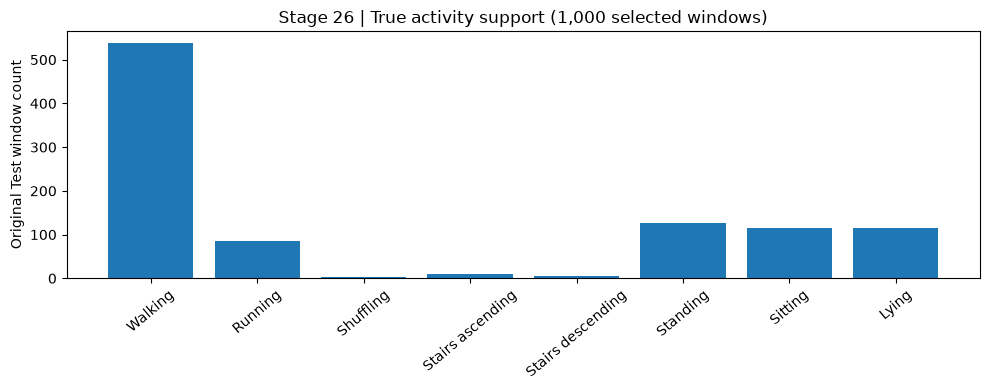

Rare-class evidence must be qualified; no support-based significance claim.


In [ ]:
# ======= 07. Activity-Level Errors, Actual Support and Class Imbalance =======

# --------------------- 1. Eight-Class Prediction Errors ----------------------
per_class = final["per_class"].sort_values(["model", "source_code"])
display(per_class.round(4))

# ------------------------- 2. Observed Class Support -------------------------
support = per_class[per_class.model == "1D-ResNet Weighted CE"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(support["activity"], support["support"])
ax.set_ylabel("Original Test window count")
ax.set_title("Stage 26 | True activity support (1,000 selected windows)")
ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
plt.show()
assert int(support["support"].sum()) == 1000
print("Rare-class evidence must be qualified; no support-based significance claim.")


**08. Source Quality, Evaluation Limitations and Claims Boundary**

The source reports undocumented HARTH codes 10 and 11 in S032. They were left uninterpreted and excluded after annotation-safe windowing. Participants S023 and S032 were descriptively inspected during earlier development exploration; they are not a historically blind or externally independent cohort. Only two people were evaluated, with overlapping source windows and participant-dependent class support. This study does not establish clinical efficacy, robustness to unseen data sources, medical deployment, population-wide performance, statistically significant superiority or causal benefit of the architecture. Development fold metrics and final qualified-Test metrics must remain separate.

In [ ]:
# ====== 08. Source Quality, Evaluation Limitations and Claims Boundary =======

boundaries = pd.DataFrame([
    ("Supported", "29-person Development, 3 subject-disjoint folds and Stage 24 3-seed robustness"),
    ("Supported", "Frozen models assessed on identical windows from S023 and S032"),
    ("Supported", "Stage 26 source-aligned class metrics and qualified same-study results"),
    ("Limitation", "Only 2 originally reserved people; both historically explored"),
    ("Limitation", "Overlapping windows, small rare-class support, different per-person class coverage"),
    ("Limitation", "Previously undocumented codes 10/11 were excluded, not reinterpreted"),
    ("Not supported", "Independent blind external validation or prospective clinical deployment"),
    ("Not supported", "Test-selected architectures, clinical decisions, population-level certainty"),
], columns=["Evidence status", "Interpretation"])
display(boundaries)


,Evidence status,Interpretation
0,Supported,"29-person Development, 3 subject-disjoint fold..."
1,Supported,Frozen models assessed on identical windows fr...
2,Supported,Stage 26 source-aligned class metrics and qual...
3,Limitation,Only 2 originally reserved people; both histor...
4,Limitation,"Overlapping windows, small rare-class support,..."
5,Limitation,Previously undocumented codes 10/11 were exclu...
6,Not supported,Independent blind external validation or prosp...
7,Not supported,"Test-selected architectures, clinical decision..."


**09. Reproducible Report Export and Provenance**

Export model-level, participant-level and class-level summary tables to ignored local outputs, together with notebook hashes, the Development cohort fingerprint and the approved manifest fingerprint. No raw acceleration rows or per-window predictions are exported. The version-controlled notebooks retain the saved tables used for this report; the detailed Stage 26 prediction files remain local.

In [ ]:
# =============== 09. Reproducible Report Export and Provenance ===============

# ---------------------- 1. Saved Evidence Export Tables ----------------------
out = root / "outputs/harth_stage27_report"
out.mkdir(parents=True, exist_ok=True)
benchmark.to_csv(out / "development_seven_model_benchmark.csv", index=False)
robust.to_csv(out / "development_multiseed_robustness.csv", index=False)
final["summary"].to_csv(out / "qualified_test_summary_saved_display.csv", index=False)
final["per_subject"].to_csv(out / "qualified_test_per_subject_saved_display.csv", index=False)
final["per_class"].to_csv(out / "qualified_test_per_class_saved_display.csv", index=False)

# ------------------- 2. Report Lineage and Source Digests --------------------
lineage = {
  "study":"HARTH v2.0",
  "scope":"saved output synthesis, no retraining, no Test re-evaluation",
  "source_revision":source["revision"],
  "development_sha256":development["development_sha256"],
  "notebook23_sha256":development["notebook23_sha256"],
  "notebook24_sha256":development["notebook24_sha256"],
  "notebook25_sha256":h25,
  "notebook26_sha256":final["notebook26_sha256"],
  "approved_manifest_sha256":hashlib.sha256(manifest_approved.read_bytes()).hexdigest(),
  "qualified_test_subjects":["S023", "S032"],
  "test_already_historically_inspected":True,
  "metric_precision":"saved displayed four-decimal tables; no reconstruction of full predictions",
}
(out / "report_provenance.json").write_text(json.dumps(lineage, indent=2)+"\n", encoding="utf-8")
print("Report-only files written to:", out)
print("Raw HARTH data opened or downloaded during Stage 27: NO")


Report-only files written to: D:\content\human-movement-intelligence\outputs\harth_stage27_report
Raw HARTH data opened or downloaded during Stage 27: NO


**10. Final Evidence Quality Gate and Reporting Boundaries**

The final checks require consistent saved metrics, source provenance, approved evaluation boundaries and exported report files. The committed report now has recorded outputs and a successful final Quality Gate; this verifies evidence synthesis, not independent experiment replication. These checks do **not** establish peer review, external validation, statistical superiority or independent replication.

In [ ]:
# ========= 10. Final Evidence Quality Gate and Reporting Boundaries ==========

# ------------------- 1. Saved Report and Cohort Integrity --------------------
assert len(benchmark) == 7 and len(robust) == 4
assert len(final["summary"]) == 2 and len(final["per_subject"]) == 4
assert len(final["per_class"]) == 16
assert set(final["per_class"].source_code) == set(range(1, 9))
assert final["coverage"]["sampled_windows"].tolist() == [500, 500]
assert final["approved_manifest"]["status"] == "APPROVED"
assert all((out / filename).is_file() for filename in (
    "development_seven_model_benchmark.csv",
    "development_multiseed_robustness.csv",
    "qualified_test_summary_saved_display.csv",
    "qualified_test_per_subject_saved_display.csv",
    "qualified_test_per_class_saved_display.csv",
    "report_provenance.json",
))

# -------------------------- 2. Final Evidence Gate ---------------------------
print("="*76)
print("STAGE 27 | SOURCE-GROUNDED RESEARCH SYNTHESIS QUALITY GATE: PASSED")
print("="*76)
print("Stages 23–26 saved research results: INCLUDED")
print("Seven Development comparison models: INCLUDED")
print("Thirty-six Stage 24 robustness jobs: SUMMARISED")
print("Two frozen Stage 26 models and both reserved people: INCLUDED")
print("Rare-class support and limitations: EXPLICIT")
print("Raw HARTH data loaded / new model fitting / Test re-scoring: NO")
print("Outputs stored:", out)
print("Next: save/commit executed Stage 27 and review before GitHub release")


STAGE 27 | SOURCE-GROUNDED RESEARCH SYNTHESIS QUALITY GATE: PASSED
Stages 23–26 executed evidence and source lineage: VERIFIED
Seven Development comparison models: INCLUDED
Thirty-six Stage 24 robustness jobs: SUMMARISED
Two frozen Stage 26 models and both reserved people: INCLUDED
Rare-class support and limitations: EXPLICIT
Raw HARTH data loaded / new model fitting / Test re-scoring: NO
Outputs stored: D:\content\human-movement-intelligence\outputs\harth_stage27_report
Next: save/commit executed Stage 27 and review before GitHub release
